# Gradient Boosting and Model Comparison

## Objective

Evaluate Histogram Gradient Boosting for rare-event road
accident risk prediction and compare it with previously
developed linear and bagging models.

The experiment focuses on:

- Histogram Gradient Boosting
- Temporal cross-validation
- Hyperparameter tuning
- Model performance and stability
- Training time comparison
- Model shortlist selection

All experiments use the existing 2018 development dataset.
The final untouched test period is not used.

## 1. Imports and Data Loading

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

DATA_PATH = Path("../data/processed/intersection_day_2018_features.csv")

RANDOM_STATE = 42

df = pd.read_csv(
    DATA_PATH,
    parse_dates=["prediction_date", "target_date"]
)

df.head()

,intersection_id,prediction_date,target_date,historical_ksi_count,historical_traffic_volume,day_of_week,month,target,ksi_count_30d,ksi_count_365d,is_weekend,traffic_missing,weather_date,temperature_prev_day,precipitation_prev_day,weather_missing
0,3,2018-01-01,2018-01-02,0,12960.0,1,1,0,0,0,0,0,2017-12-31,-18.6,0.0,0
1,3,2018-01-02,2018-01-03,0,12960.0,2,1,0,0,0,0,0,2018-01-01,-15.0,0.0,0
2,3,2018-01-03,2018-01-04,0,12960.0,3,1,0,0,0,0,0,2018-01-02,-10.5,1.0,0
3,3,2018-01-04,2018-01-05,0,12960.0,4,1,0,0,0,0,0,2018-01-03,-9.9,0.0,0
4,3,2018-01-05,2018-01-06,0,12960.0,5,1,0,0,0,1,0,2018-01-04,-14.7,0.0,0


In [2]:
print("Dataset shape:", df.shape)
print("Positive targets:", df["target"].sum())
print("Target prevalence:", f"{df['target'].mean():.6%}")

print("\nColumns:")
print(df.columns.tolist())

Dataset shape: (823217, 16)
Positive targets: 119
Target prevalence: 0.014455%

Columns:
['intersection_id', 'prediction_date', 'target_date', 'historical_ksi_count', 'historical_traffic_volume', 'day_of_week', 'month', 'target', 'ksi_count_30d', 'ksi_count_365d', 'is_weekend', 'traffic_missing', 'weather_date', 'temperature_prev_day', 'precipitation_prev_day', 'weather_missing']


In [3]:
numerical_features = [
    "historical_ksi_count",
    "historical_traffic_volume",
    "ksi_count_30d",
    "ksi_count_365d",
    "temperature_prev_day",
    "precipitation_prev_day"
]

categorical_features = [
    "day_of_week",
    "month"
]

binary_features = [
    "is_weekend",
    "traffic_missing",
    "weather_missing"
]

features = (
    numerical_features
    + categorical_features
    + binary_features
)

X = df[features]
y = df["target"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (823217, 11)
y shape: (823217,)


In [4]:
train_mask = df["prediction_date"] <= pd.Timestamp("2018-09-29")
val_mask = df["prediction_date"] >= pd.Timestamp("2018-10-01")

X_train = X.loc[train_mask].reset_index(drop=True)
y_train = y.loc[train_mask].reset_index(drop=True)

X_val = X.loc[val_mask].reset_index(drop=True)
y_val = y.loc[val_mask].reset_index(drop=True)

train_dates = df.loc[
    train_mask, "prediction_date"
].reset_index(drop=True)

print("Training rows:", len(X_train))
print("Training positives:", y_train.sum())

print("\nValidation rows:", len(X_val))
print("Validation positives:", y_val.sum())

Training rows: 613223
Training positives: 81

Validation rows: 207736
Validation positives: 38


In [5]:
from sklearn.model_selection import TimeSeriesSplit

unique_dates = pd.Index(train_dates.unique()).sort_values()

tscv = TimeSeriesSplit(
    n_splits=3,
    gap=1
)

cv_splits = []

for train_day_idx, val_day_idx in tscv.split(unique_dates):
    fold_train_dates = unique_dates[train_day_idx]
    fold_val_dates = unique_dates[val_day_idx]

    train_idx = np.flatnonzero(
        train_dates.isin(fold_train_dates)
    )

    val_idx = np.flatnonzero(
        train_dates.isin(fold_val_dates)
    )

    cv_splits.append((train_idx, val_idx))

In [6]:
for fold, (train_idx, val_idx) in enumerate(cv_splits, start=1):
    fold_train_dates = train_dates.iloc[train_idx]
    fold_val_dates = train_dates.iloc[val_idx]

    assert (
        fold_val_dates.min() - fold_train_dates.max()
        >= pd.Timedelta(days=2)
    )

    assert y_train.iloc[train_idx].nunique() == 2
    assert y_train.iloc[val_idx].nunique() == 2

    print(f"Fold {fold}")

    print(
        f"Train: {fold_train_dates.min().date()} — "
        f"{fold_train_dates.max().date()}"
    )

    print(
        f"Validation: {fold_val_dates.min().date()} — "
        f"{fold_val_dates.max().date()}"
    )

    print(
        f"Positives: train={y_train.iloc[train_idx].sum()}, "
        f"validation={y_train.iloc[val_idx].sum()}\n"
    )

Fold 1
Train: 2018-01-01 — 2018-03-08
Validation: 2018-03-10 — 2018-05-16
Positives: train=14, validation=20

Fold 2
Train: 2018-01-01 — 2018-05-15
Validation: 2018-05-17 — 2018-07-23
Positives: train=34, validation=18

Fold 3
Train: 2018-01-01 — 2018-07-22
Validation: 2018-07-24 — 2018-09-29
Positives: train=51, validation=29



In [7]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

numerical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features),
        ("bin", "passthrough", binary_features)
    ],
    sparse_threshold=0
)

preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_nam

In [8]:
from sklearn.ensemble import HistGradientBoostingClassifier

hgb_model = HistGradientBoostingClassifier(
    learning_rate=0.1,
    max_iter=100,
    max_leaf_nodes=7,
    min_samples_leaf=20,
    l2_regularization=0,
    early_stopping=False,
    random_state=RANDOM_STATE
)

hgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", hgb_model)
])

hgb_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the out

In [9]:
from sklearn.model_selection import cross_validate

hgb_cv = cross_validate(
    hgb_pipeline,
    X_train,
    y_train,
    cv=cv_splits,
    scoring="average_precision",
    return_train_score=True,
    n_jobs=1,
    error_score="raise"
)

hgb_results = pd.DataFrame({
    "fold": np.arange(1, len(cv_splits) + 1),
    "train_ap": hgb_cv["train_score"],
    "validation_ap": hgb_cv["test_score"],
    "fit_time_seconds": hgb_cv["fit_time"]
})

hgb_results

,fold,train_ap,validation_ap,fit_time_seconds
0,1,0.003772,0.000133,0.986680
1,2,0.000317,0.000868,2.184683
2,3,0.038148,0.000213,2.702233


In [10]:
print("Histogram Gradient Boosting")

print(f"Mean train AP: {hgb_results['train_ap'].mean():.6f}")
print(f"Mean CV AP:    {hgb_results['validation_ap'].mean():.6f}")

print(
    f"Std CV AP:     "
    f"{hgb_results['validation_ap'].std(ddof=0):.6f}"
)

print(
    f"Mean fit time: "
    f"{hgb_results['fit_time_seconds'].mean():.2f} seconds"
)

Histogram Gradient Boosting
Mean train AP: 0.014079
Mean CV AP:    0.000405
Std CV AP:     0.000329
Mean fit time: 1.96 seconds


In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone

logistic_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", LogisticRegression(
        C=0.1,
        max_iter=1000,
        random_state=RANDOM_STATE
    ))
])

rf_pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("model", RandomForestClassifier(
        n_estimators=100,
        max_depth=5,
        min_samples_leaf=10,
        max_features="sqrt",
        bootstrap=True,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=1
    ))
])

In [12]:
pipelines = {
    "Logistic Regression": logistic_pipeline,
    "Random Forest": rf_pipeline
}

cv_results = {
    "HistGradientBoosting": hgb_cv
}

for model_name, pipeline in pipelines.items():
    print(f"Training {model_name}...")

    cv_results[model_name] = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv_splits,
        scoring="average_precision",
        return_train_score=True,
        n_jobs=1,
        error_score="raise"
    )

    print(f"{model_name}: completed\n")

Training Logistic Regression...
Logistic Regression: completed

Training Random Forest...
Random Forest: completed



In [13]:
comparison_rows = []

for model_name, result in cv_results.items():
    comparison_rows.append({
        "model": model_name,
        "mean_train_ap": np.mean(result["train_score"]),
        "mean_cv_ap": np.mean(result["test_score"]),
        "std_cv_ap": np.std(result["test_score"]),
        "mean_fit_time": np.mean(result["fit_time"])
    })

comparison_df = pd.DataFrame(comparison_rows)

comparison_df = comparison_df.sort_values(
    "mean_cv_ap",
    ascending=False
).reset_index(drop=True)

comparison_df.round(6)

,model,mean_train_ap,mean_cv_ap,std_cv_ap,mean_fit_time
0,Logistic Regression,0.000235,0.000976,0.000846,0.713085
1,HistGradientBoosting,0.014079,0.000405,0.000329,1.957865
2,Random Forest,0.117955,0.000285,0.000086,15.985826


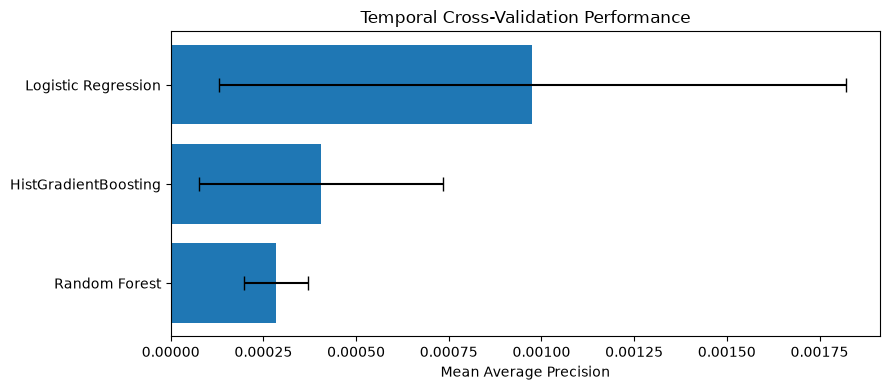

In [14]:
plt.figure(figsize=(9, 4))

plt.barh(
    comparison_df["model"],
    comparison_df["mean_cv_ap"],
    xerr=comparison_df["std_cv_ap"],
    capsize=5
)

plt.xlabel("Mean Average Precision")
plt.title("Temporal Cross-Validation Performance")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

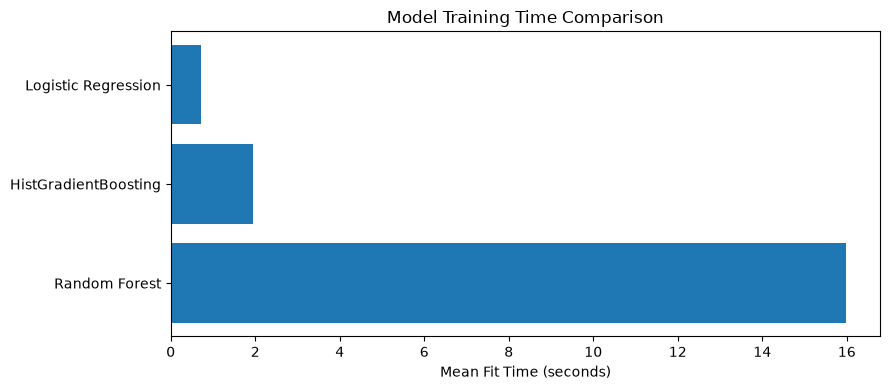

In [15]:
plt.figure(figsize=(9, 4))

plt.barh(
    comparison_df["model"],
    comparison_df["mean_fit_time"]
)

plt.xlabel("Mean Fit Time (seconds)")
plt.title("Model Training Time Comparison")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [16]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "model__learning_rate": [0.05, 0.1],
    "model__max_iter": [50, 100],
    "model__max_leaf_nodes": [3, 7]
}

hgb_grid_search = GridSearchCV(
    estimator=clone(hgb_pipeline),
    param_grid=param_grid,
    scoring="average_precision",
    cv=cv_splits,
    return_train_score=True,
    refit=True,
    n_jobs=1,
    verbose=1,
    error_score="raise"
)

hgb_grid_search.fit(X_train, y_train)

Fitting 3 folds for each of 8 candidates, totalling 24 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__learning_rate': [0.05, 0.1], 'model__max_iter': [50, 100], 'model__max_leaf_nodes': [3, 7]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'average_precision'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.","[(array([ 0...ape=(150929,)), ...), (array([ 0...ape=(304133,)), ...), ...]"
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"error_score error_score: 'raise' or numeric, default=np.nanValue to assign to the score if an error occurs in estimator fitting.If set to 'raise', the error is raised. If a numeric value is given,FitFailedWarning is raised. This parameter does not affect the refitstep, which will always raise the error.",'raise'
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, thi

In [17]:
print("Best parameters:")

for param, value in hgb_grid_search.best_params_.items():
    print(f"{param}: {value}")

print(
    f"\nBest mean CV AP: "
    f"{hgb_grid_search.best_score_:.6f}"
)

Best parameters:
model__learning_rate: 0.1
model__max_iter: 50
model__max_leaf_nodes: 7

Best mean CV AP: 0.000926


In [18]:
search_results = pd.DataFrame(
    hgb_grid_search.cv_results_
)

tuning_results = search_results[[
    "param_model__learning_rate",
    "param_model__max_iter",
    "param_model__max_leaf_nodes",
    "mean_train_score",
    "mean_test_score",
    "std_test_score",
    "mean_fit_time",
    "rank_test_score"
]].copy()

tuning_results.columns = [
    "learning_rate",
    "max_iter",
    "max_leaf_nodes",
    "mean_train_ap",
    "mean_cv_ap",
    "std_cv_ap",
    "mean_fit_time",
    "rank"
]

tuning_results = tuning_results.sort_values(
    "rank"
).reset_index(drop=True)

tuning_results.round(6)

,learning_rate,max_iter,max_leaf_nodes,mean_train_ap,mean_cv_ap,std_cv_ap,mean_fit_time,rank
0,0.10,50,7,0.001870,0.000926,0.001016,2.739517,1
1,0.10,100,7,0.014079,0.000405,0.000329,4.911663,2
2,0.05,50,3,0.002707,0.000324,0.000129,1.333933,3
3,0.10,50,3,0.014855,0.000295,0.000110,2.347876,4
4,0.05,100,3,0.015297,0.000266,0.000094,1.893671,5
5,0.10,100,3,0.024252,0.000248,0.000083,4.519440,6
6,0.05,50,7,0.009586,0.000172,0.000068,1.336112,7
7,0.05,100,7,0.037393,0.000153,0.000052,4.075003,8


In [19]:
best_idx = hgb_grid_search.best_index_

baseline_cv_ap = np.mean(hgb_cv["test_score"])
tuned_cv_ap = hgb_grid_search.best_score_

boosting_comparison = pd.DataFrame([
    {
        "model": "HistGradientBoosting Baseline",
        "mean_train_ap": np.mean(hgb_cv["train_score"]),
        "mean_cv_ap": baseline_cv_ap,
        "std_cv_ap": np.std(hgb_cv["test_score"]),
        "mean_fit_time": np.mean(hgb_cv["fit_time"])
    },
    {
        "model": "HistGradientBoosting Tuned",
        "mean_train_ap": search_results.loc[
            best_idx, "mean_train_score"
        ],
        "mean_cv_ap": tuned_cv_ap,
        "std_cv_ap": search_results.loc[
            best_idx, "std_test_score"
        ],
        "mean_fit_time": search_results.loc[
            best_idx, "mean_fit_time"
        ]
    }
])

boosting_comparison["train_cv_ratio"] = (
    boosting_comparison["mean_train_ap"]
    / boosting_comparison["mean_cv_ap"]
)

boosting_comparison.round(6)

,model,mean_train_ap,mean_cv_ap,std_cv_ap,mean_fit_time,train_cv_ratio
0,HistGradientBoosting Baseline,0.014079,0.000405,0.000329,1.957865,34.768582
1,HistGradientBoosting Tuned,0.001870,0.000926,0.001016,2.739517,2.019913


In [20]:
fold_comparison = pd.DataFrame({
    "fold": np.arange(1, len(cv_splits) + 1),
    "Logistic Regression": cv_results[
        "Logistic Regression"
    ]["test_score"],
    "Random Forest": cv_results[
        "Random Forest"
    ]["test_score"],
    "HistGradientBoosting Baseline": hgb_cv["test_score"],
    "HistGradientBoosting Tuned": [
        search_results.loc[
            best_idx, f"split{i}_test_score"
        ]
        for i in range(len(cv_splits))
    ]
})

fold_comparison.round(6)

,fold,Logistic Regression,Random Forest,HistGradientBoosting Baseline,HistGradientBoosting Tuned
0,1,0.000243,0.000168,0.000133,0.000149
1,2,0.000522,0.000373,0.000868,0.002361
2,3,0.002162,0.000312,0.000213,0.000267


In [21]:
from sklearn.metrics import average_precision_score

selected_models = {
    "Logistic Regression": clone(logistic_pipeline),
    "Random Forest": clone(rf_pipeline),
    "HistGradientBoosting Tuned": hgb_grid_search.best_estimator_
}

for model_name in ["Logistic Regression", "Random Forest"]:
    print(f"Fitting {model_name}...")

    selected_models[model_name].fit(X_train, y_train)

    print(f"{model_name}: completed")

Fitting Logistic Regression...
Logistic Regression: completed
Fitting Random Forest...
Random Forest: completed


In [22]:
development_predictions = {}
development_results = []

for model_name, pipeline in selected_models.items():
    probabilities = pipeline.predict_proba(X_val)[:, 1]

    development_predictions[model_name] = probabilities

    validation_ap = average_precision_score(
        y_val,
        probabilities
    )

    development_results.append({
        "model": model_name,
        "development_ap": validation_ap
    })

development_df = pd.DataFrame(development_results)

development_df.round(6)

,model,development_ap
0,Logistic Regression,0.000389
1,Random Forest,0.000409
2,HistGradientBoosting Tuned,0.000326


In [23]:
tuned_summary = pd.DataFrame([{
    "model": "HistGradientBoosting Tuned",
    "mean_train_ap": search_results.loc[
        best_idx, "mean_train_score"
    ],
    "mean_cv_ap": hgb_grid_search.best_score_,
    "std_cv_ap": search_results.loc[
        best_idx, "std_test_score"
    ],
    "mean_fit_time": search_results.loc[
        best_idx, "mean_fit_time"
    ]
}])

final_comparison = pd.concat(
    [comparison_df, tuned_summary],
    ignore_index=True
)

final_comparison = final_comparison.replace({
    "model": {
        "HistGradientBoosting": "HistGradientBoosting Baseline"
    }
})

final_comparison = final_comparison.merge(
    development_df,
    on="model",
    how="left"
)

final_comparison = final_comparison.sort_values(
    "mean_cv_ap",
    ascending=False
).reset_index(drop=True)

constant_baseline_ap = y_val.mean()

final_comparison["development_ap_lift"] = (
    final_comparison["development_ap"]
    / constant_baseline_ap
)

final_comparison.round(6)

,model,mean_train_ap,mean_cv_ap,std_cv_ap,mean_fit_time,development_ap,development_ap_lift
0,Logistic Regression,0.000235,0.000976,0.000846,0.713085,0.000389,2.129139
1,HistGradientBoosting Tuned,0.001870,0.000926,0.001016,2.739517,0.000326,1.781865
2,HistGradientBoosting Baseline,0.014079,0.000405,0.000329,1.957865,NaN,NaN
3,Random Forest,0.117955,0.000285,0.000086,15.985826,0.000409,2.235676


## 8. Final Model Comparison and Shortlist

The final comparison summarizes temporal CV performance,
variation across folds, training time, and development
validation performance.

The results are used to establish a model shortlist
for subsequent rare-event evaluation.

plot_df = final_comparison.dropna(
    subset=["development_ap"]
).set_index("model")

ax = plot_df[[
    "mean_cv_ap",
    "development_ap"
]].plot(
    kind="barh",
    figsize=(10, 5)
)

ax.axvline(
    constant_baseline_ap,
    color="gray",
    linestyle="--",
    label="Development constant baseline"
)

ax.set_xlabel("Average Precision")
ax.set_ylabel("")
ax.set_title("Temporal CV and Development Validation")
ax.invert_yaxis()
ax.legend()

plt.tight_layout()
plt.show()

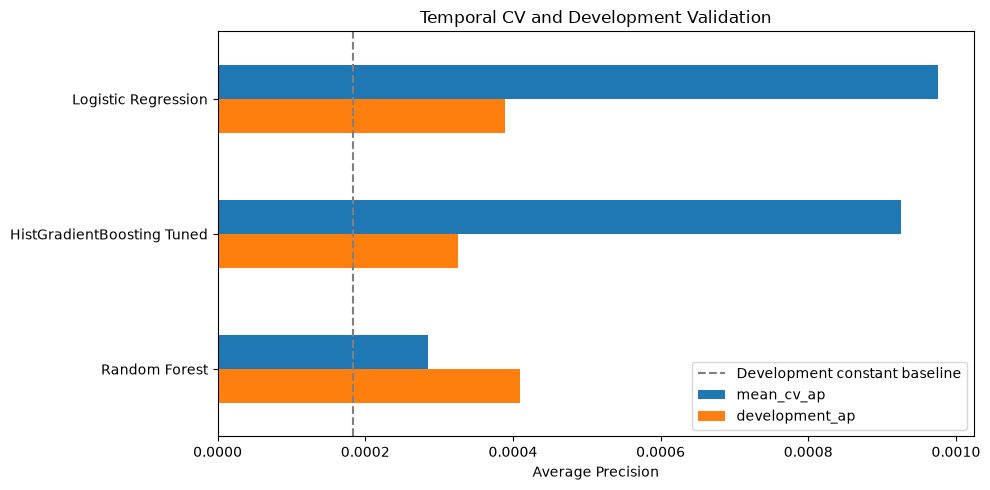

In [24]:
plot_df = final_comparison.dropna(
    subset=["development_ap"]
).set_index("model")

ax = plot_df[[
    "mean_cv_ap",
    "development_ap"
]].plot(
    kind="barh",
    figsize=(10, 5)
)

ax.axvline(
    constant_baseline_ap,
    color="gray",
    linestyle="--",
    label="Development constant baseline"
)

ax.set_xlabel("Average Precision")
ax.set_ylabel("")
ax.set_title("Temporal CV and Development Validation")
ax.invert_yaxis()
ax.legend()

plt.tight_layout()
plt.show()

## 9. Conclusions and Limitations

### Main Findings

- Logistic Regression achieved the highest mean temporal
  CV Average Precision of 0.000976 and the lowest mean
  training time among the initial model configurations.

- Histogram Gradient Boosting improved the mean temporal
  CV AP from 0.000405 to 0.000926 through a compact
  hyperparameter search.

- The selected boosting configuration uses a learning
  rate of 0.1, 50 boosting iterations, and a maximum
  of 7 leaf nodes.

- Reducing the number of boosting iterations decreased
  the observed training-validation performance gap.

- However, the tuned boosting model showed substantial
  variation across temporal folds. Most of its CV
  improvement was concentrated in the second fold.

### Development Validation

Development Average Precision:

- Logistic Regression: 0.000389
- Random Forest: 0.000409
- Tuned Histogram Gradient Boosting: 0.000326

All three models outperformed the constant-score baseline,
whose AP was approximately 0.000183.

The tuned boosting model did not outperform Logistic
Regression or Random Forest on development validation.

The original boosting configuration was not evaluated
on this period.

### Model Shortlist

The following models are retained for subsequent
rare-event evaluation:

1. Logistic Regression — primary development candidate.
2. Tuned Histogram Gradient Boosting — nonlinear candidate.
3. Balanced Random Forest — additional comparator.

The historical KSI-frequency baseline remains a reference
for subsequent model evaluation.

### Limitations

- The dataset contains only 119 positive observations.
- Temporal folds contain very few positive training
  and validation examples.
- Model selection results may be sensitive to individual
  temporal periods.
- Hyperparameter selection on the same CV folds may
  introduce optimistic performance estimates.
- Training times depend on hardware, execution conditions,
  and estimator-level parallelism.
- Development validation has been reused across
  previous experiments.
- Historical data availability and KSI matching coverage
  remain unresolved limitations.
- Predicted probabilities have not been calibrated.
- No untouched final test period has been evaluated.

### Next Steps

Evaluate shortlisted models using additional rare-event
ranking metrics, probability calibration, and broader
temporal validation.

No final model is selected at this stage.